# 04 · Backtest order-level su Nasdaq ITCH (E3)

Stima principale: la quota virtuale entra in coda dietro tutto il volume presente al suo prezzo; le cancellazioni davanti accorciano la coda, le esecuzioni la consumano, e la quota è eseguita solo da esecuzioni che la raggiungono (fill anche parziali). Le tre regole L2 sono simulate sulla vista L2 dello **stesso** feed.

Calibrazione delle soglie: 30/01/2019. Validazione: 27/03/2019. Test: 5 giornate dal 30/07/2019 al 30/01/2020 (15 sessioni titolo-giorno, sessione regolare 09:30-16:00, 100 azioni per lato). Costi Nasdaq di riferimento: rebate di 0,20 cent/azione al maker, 0,30 cent/azione al taker.

**Validazione**: P&L netto medio per sessione con coda FIFO (USD)

Parametri scelti: `{'vol_quantile': 0.5, 'max_order_age_ns': 30000000000, 'volatility_window': 120}` (finestra in secondi, durata in nanosecondi).

,sessioni,media,ic95_basso,ic95_alto,quota_positive
touch,15,112107.93,98080.08,129036.57,1.00
price-through,15,-533.60,-807.00,-95.06,0.07
cross,15,-1400.93,-1935.88,-945.26,0.00
coda FIFO,15,-570.29,-695.13,-458.40,0.00


**Fill maker rispetto alla coda FIFO** (mediana e intervallo tra le sessioni)

model,touch,price-through,cross,coda FIFO
50%,105.99,1.09,1.05,1.0
min,44.97,0.87,0.85,1.0
max,384.69,3.19,1.59,1.0


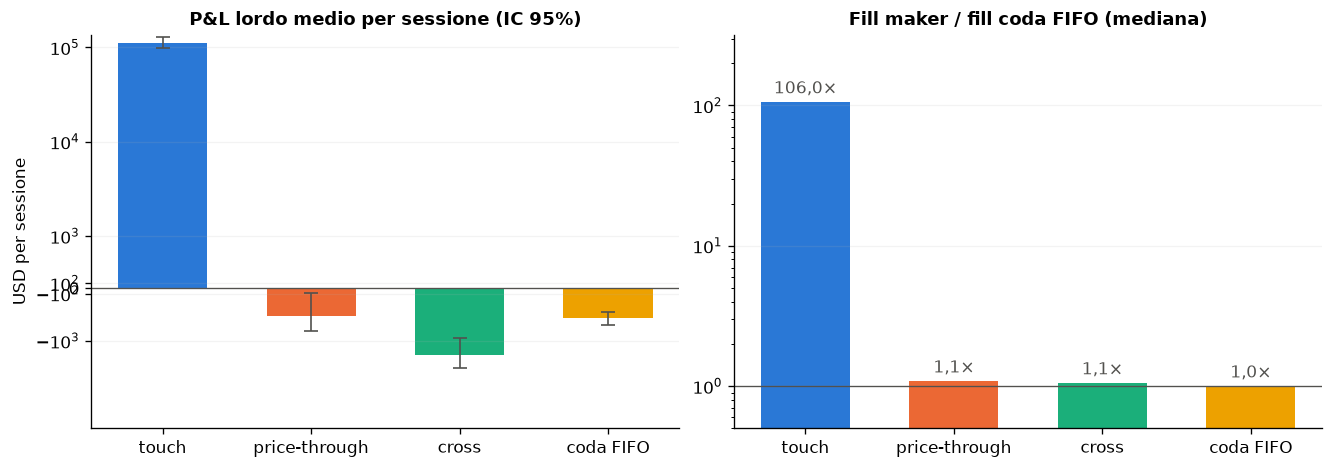

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / "src/market_making_tesi").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from market_making_tesi import report as R
from market_making_tesi.report import it, pct
R.setup_plots()
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
np.random.seed(0)
test = R.load(ROOT, "test")
validation = R.load(ROOT, "validation")
selected = R.load_json(ROOT, "selected_params")

def dataset_section(name, fee_column, unit):
    stats = R.model_table(test, name)
    display(stats.round(2))
    bias = R.fill_bias(test, name)
    display(Markdown("**Fill maker rispetto alla coda FIFO** (mediana e intervallo tra le sessioni)"))
    display(bias.describe().loc[["50%", "min", "max"]].rename(columns=R.LABELS).round(2))
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
    R.bar_by_model(axes[0], stats, "P&L lordo medio per sessione (IC 95%)", unit)
    linthresh = 10 ** np.ceil(np.log10(max(1.0, abs(stats.loc["coda FIFO", "media"]))))
    axes[0].set_yscale("symlog", linthresh=linthresh, linscale=0.5)
    med = bias.median()
    axes[1].bar([R.LABELS[m] for m in med.index], med, color=[R.COLORS[m] for m in med.index], width=0.6)
    for k, v in enumerate(med):
        axes[1].text(k, v * 1.08, f"{it(v, 1)}×", ha="center", va="bottom", color=R.INK)
    axes[1].axhline(1, color=R.INK, linewidth=0.8)
    axes[1].set(yscale="log", title="Fill maker / fill coda FIFO (mediana)", ylim=(0.5, med.max() * 3))
    axes[1].grid(axis="x", visible=False)
    return stats, fig

display(Markdown("**Validazione**: P&L netto medio per sessione con coda FIFO (USD)"))
display(R.validation_grid(validation, "itch", "net_nasdaq_base").style.format("{:.1f}").background_gradient(cmap="Greys", axis=None))
display(Markdown(f"Parametri scelti: `{selected['itch']['params']}` (finestra in secondi, durata in nanosecondi)."))
stats, fig = dataset_section("itch", "fees_nasdaq_base", "USD per sessione")
fig.savefig(FIGURES / "itch_test.png", dpi=180, bbox_inches="tight")
plt.show()

## Da dove viene il risultato

Scomposizione media per sessione: edge maker (spread incassato rispetto al midpoint), costo di liquidazione (attraversamento dello spread per chiudere l'inventario), P&L di inventario (movimento del prezzo durante la detenzione) e commissioni (con il rebate maker sono negative per chi fornisce liquidità). L'**adverse selection** è il markout dopo 100 record dal fill.

In [2]:
dec = R.decomposition(test, "itch", "fees_nasdaq_base")
display(dec.rename(columns={**R.DECOMPOSITION_LABELS, "final_equity": "P&L lordo", "adverse_selection": "adverse selection (markout)", "net": "P&L netto"}).round(2))
display(R.fill_rates(test, "itch").style.format({"coppie": "{:,.0f}", **{c: "{:.1%}" for c in ["bilaterali", "unilaterali", "senza fill", "con fill parziale"]}}))
mk = test[test.dataset == "itch"].groupby("model")[["markout_bid_mean", "markout_ask_mean"]].mean()
mk.index = [R.LABELS[m] for m in mk.index]
display(Markdown("**Markout medio per azione dopo i fill (USD; negativo = il prezzo si muove contro la quota)**"))
display(mk.round(4))

,edge maker,costo di liquidazione,P&L di inventario,P&L lordo,adverse selection (markout),commissioni,P&L netto
touch,112494.37,-288.20,-98.23,112107.93,10.57,26978.49,139086.43
price-through,477.97,-367.83,-643.73,-533.60,-547.20,140.81,-392.79
cross,-839.83,-382.87,-178.23,-1400.93,-131.53,95.82,-1305.11
coda FIFO,437.02,-268.61,-738.69,-570.29,-693.87,29.70,-540.59


,coppie,bilaterali,unilaterali,senza fill,con fill parziale
touch,"1,018,516",99.5%,0.5%,0.0%,0.0%
price-through,"14,747",47.8%,48.0%,4.2%,0.0%
cross,"13,180",40.9%,54.5%,4.7%,0.0%
coda FIFO,"10,990",26.0%,47.7%,26.3%,11.7%


**Markout medio per azione dopo i fill (USD; negativo = il prezzo si muove contro la quota)**

,markout_bid_mean,markout_ask_mean
cross,-0.0010,-0.0006
price-through,-0.0040,-0.0038
coda FIFO,-0.0104,-0.0096
touch,-0.0000,0.0000


In [3]:
queue = test[(test.dataset == "itch") & (test.model == "queue")]
display(queue.pivot_table(index="session", columns="symbol", values="net_nasdaq_base").round(1))
per_symbol = queue.groupby("symbol").agg(sessioni=("session", "size"), netto_medio=("net_nasdaq_base", "mean"),
                                         positive=("net_nasdaq_base", lambda x: (x > 0).mean()),
                                         coppie=("pairs_placed", "sum"), inventario_max=("max_abs_inventory_seen", "max"))
display(per_symbol.round(2))

symbol,AAPL,INTC,MSFT
session,,,
2019-07-30,-542.0,-354.6,-533.9
2019-08-30,-923.0,-368.1,-344.9
2019-10-30,-966.9,-379.6,-404.5
2019-12-30,-898.1,-343.3,-544.8
2020-01-30,-762.0,-401.2,-341.7


,sessioni,netto_medio,positive,coppie,inventario_max
symbol,,,,,
AAPL,5,-818.41,0.0,3996,100.0
INTC,5,-369.38,0.0,3463,100.0
MSFT,5,-433.97,0.0,3531,100.0


## Filtro di volatilità: regime e contributo

Su ITCH la volatilità è misurata in tempo di calendario: midpoint campionato ogni secondo, finestra di *W* secondi. Misurarla per messaggio darebbe stime artificialmente basse all'apertura, quando migliaia di inserimenti e cancellazioni non muovono il prezzo, e soglie poco rappresentative del resto della sessione. Il grafico mostra una sessione di test con la strategia selezionata: in grigio i periodi in cui la volatilità supera la soglia e la strategia non opera. La tabella confronta, sessione per sessione, la strategia con filtro e la stessa strategia sempre attiva.

Con la soglia q75 la strategia sarebbe attiva nel 96% della sessione.

Con la soglia q90 la strategia sarebbe attiva nel 98% della sessione.

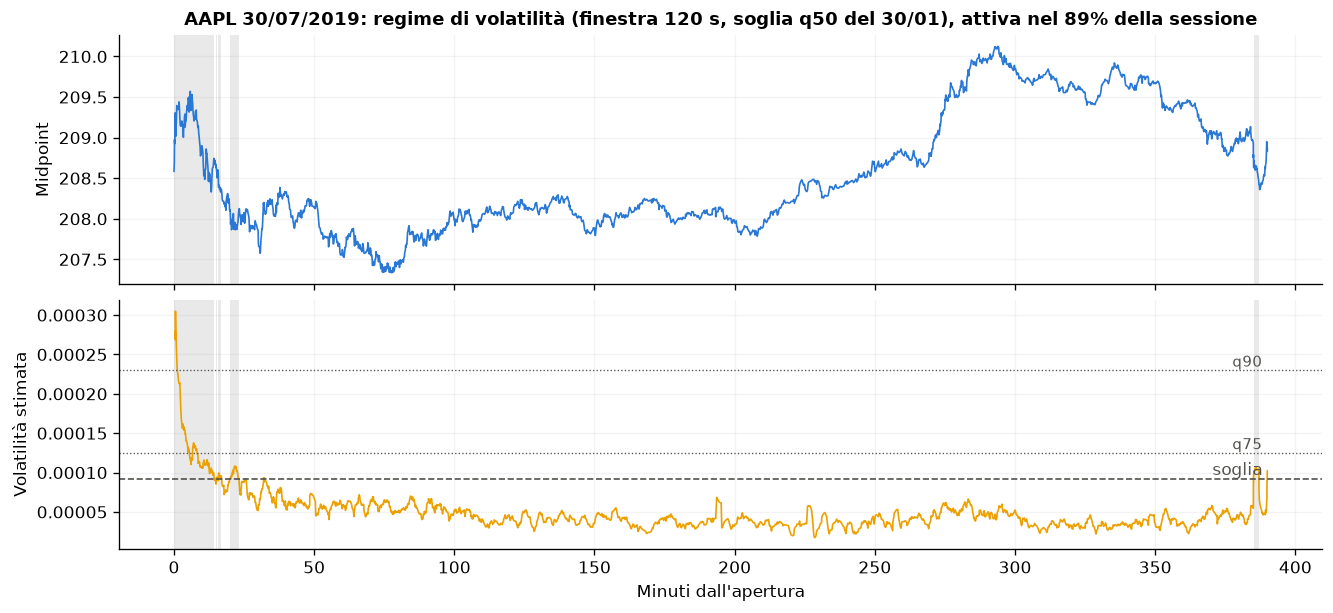

**P&L netto per sessione (USD): con filtro e sempre attiva**

,sessioni,con filtro,sempre attiva,differenza,IC95 basso,IC95 alto,sessioni migliori con filtro,quota record attivi,fill con filtro,fill sempre attiva,liquidazioni per volatilità
modello,,,,,,,,,,,
touch,15,"139,086.4","171,576.4","-32,490.0","-45,233.1","-21,171.0",0%,71%,"135,438","155,526",39.5
price-through,15,-392.8,-412.9,20.1,-295.5,238.0,73%,71%,"1,411","1,870",37.7
cross,15,"-1,305.1","-1,786.3",481.1,259.3,761.6,100%,71%,"1,197","1,558",37.3
coda FIFO,15,-540.6,-691.8,151.2,59.7,259.5,80%,71%,"1,071","1,382",21.3


In [4]:
row = test[(test.dataset == "itch") & (test.model == "queue") & (test.session == "2019-07-30") & (test.symbol == "AAPL")].iloc[0]
cal = R.load(ROOT, "calibration").set_index(["dataset", "session", "symbol"]).loc[("itch", "2019-07-30", "AAPL")]
equity = pd.read_csv(ROOT / "results/runs/itch/2019-07-30_AAPL/queue/equity.csv")
minutes = (equity.timestamp - 34_200 * 10**9) / 6e10
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True, layout="constrained")
R.plot_regime(axes, equity, row.volatility_threshold, minutes, None, "Minuti dall'apertura")
ref = R.load(ROOT, "calibration").set_index(["dataset", "session", "symbol"]).loc[("itch", "2019-01-30", "AAPL")]
window = int(row.param_volatility_window)
for q in [q for q in (50, 75, 90) if q != round(100 * row.param_vol_quantile)]:
    level = ref[f"threshold_w{window}_q{q}"]
    axes[1].axhline(level, color=R.INK, linewidth=0.8, linestyle=":")
    axes[1].text(minutes.iloc[-1], level, f"q{q} ", va="bottom", ha="right", color=R.INK, fontsize=9)
    display(Markdown(f"Con la soglia q{q} la strategia sarebbe attiva nel {pct((equity.volatility.dropna() <= level).mean(), 0)} della sessione."))
axes[0].set_title(f"AAPL 30/07/2019: regime di volatilità (finestra {int(row.param_volatility_window)} s, "
                  f"soglia q{int(100 * row.param_vol_quantile)} del 30/01), attiva nel {pct(row.active_share, 0)} della sessione")
fig.savefig(FIGURES / "itch_regime_volatilita.png", dpi=180, bbox_inches="tight")
plt.show()
ablation = R.load(ROOT, "ablation")
effect = R.filter_effect(test, ablation, "itch", "net_nasdaq_base")
FMT = {c: "{:,.1f}" for c in ["con filtro", "sempre attiva", "differenza", "IC95 basso", "IC95 alto"]} | {
    "sessioni migliori con filtro": "{:.0%}", "quota record attivi": "{:.0%}", "fill con filtro": "{:,.0f}",
    "fill sempre attiva": "{:,.0f}", "liquidazioni per volatilità": "{:.1f}"}
display(Markdown("**P&L netto per sessione (USD): con filtro e sempre attiva**"))
display(effect.style.format(FMT))

## Varianti: inventory skew e filtro di imbalance

Stesse sessioni di test e stessi parametri base; cambia solo la gestione dell'inventario (skew) o la condizione di quotazione (imbalance). Coda FIFO, P&L netto con costi Nasdaq; la differenza è appaiata con la strategia base.

In [5]:
variants = R.load(ROOT, "variants")
display(R.variant_effect(test, variants, "itch", "net_nasdaq_base", fee_column="fees_nasdaq_base").style.format({"P&L netto medio": "{:,.2f}", "IC95 basso": "{:,.2f}", "IC95 alto": "{:,.2f}", "sessioni positive": "{:.0%}",
       "differenza vs base": "{:+,.2f}", "diff IC95 basso": "{:+,.2f}", "diff IC95 alto": "{:+,.2f}",
       "edge maker": "{:,.2f}", "costo di liquidazione": "{:,.2f}", "P&L di inventario": "{:,.2f}",
       "commissioni": "{:,.2f}", "fill maker": "{:,.0f}", "coppie bilaterali": "{:.0%}", "liquidazioni a mercato": "{:,.1f}"}))
display(Markdown(f"Parametri scelti in validazione: `{selected['variants']['itch']}`"))

,sessioni,P&L netto medio,IC95 basso,IC95 alto,sessioni positive,differenza vs base,diff IC95 basso,diff IC95 alto,edge maker,costo di liquidazione,P&L di inventario,commissioni,fill maker,coppie bilaterali,liquidazioni a mercato
variante,,,,,,,,,,,,,,,
base,15,-540.59,-659.64,-434.79,0%,+0.00,+0.00,+0.00,437.02,-268.61,-738.69,29.70,"1,071",26%,391.9
inventory skew,15,-144.48,-243.25,-67.88,13%,+396.10,+298.01,+513.34,271.95,-22.13,-470.21,75.91,692,62%,29.1
filtro di imbalance,15,-259.19,-401.71,-131.80,0%,+281.39,+224.45,+338.81,371.20,-465.52,-117.14,-47.73,619,0%,524.2
skew + imbalance,15,-70.75,-144.73,-8.06,13%,+469.84,+388.61,+559.29,226.07,-18.33,-330.09,51.60,400,3%,24.8


Parametri scelti in validazione: `{'imbalance': {'params': {'imbalance_threshold': 0.3}, 'validation_mean': -116.9536666666686, 'metric': 'net_nasdaq_base'}, 'skew': {'params': {'inventory_mode': 'skew', 'skew_ticks': 1, 'max_hold_factor': 10}, 'validation_mean': -117.72433333333703, 'metric': 'net_nasdaq_base'}, 'skew_imbalance': {'params': {'inventory_mode': 'skew', 'skew_ticks': 0, 'max_hold_factor': 10, 'imbalance_threshold': 0.3}, 'validation_mean': -70.41233333333436, 'metric': 'net_nasdaq_base'}}`

In [6]:
s, q = stats, stats.loc["coda FIFO"]
bias = R.fill_bias(test, "itch").median()
display(Markdown(
    f"**Esito E3.** Con la coda FIFO il P&L lordo medio è {it(q['media'], 1)} USD per sessione "
    f"(IC 95% {it(q['ic95_basso'], 1)}; {it(q['ic95_alto'], 1)}), positivo nel {pct(q['quota_positive'], 0)} delle sessioni di test. "
    f"`touch` attribuisce {it(bias['touch'])} volte i fill della coda e un P&L di {it(s.loc['touch', 'media'])} USD; "
    f"`price-through` e `cross` sono vicine nel numero di fill ({it(bias['price-through'], 1)}× e {it(bias['cross'], 1)}×) ma non nel P&L."))

**Esito E3.** Con la coda FIFO il P&L lordo medio è -570,3 USD per sessione (IC 95% -695,1; -458,4), positivo nel 0% delle sessioni di test. `touch` attribuisce 106 volte i fill della coda e un P&L di 112.108 USD; `price-through` e `cross` sono vicine nel numero di fill (1,1× e 1,1×) ma non nel P&L.